In [15]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [16]:
# state is shared memory across the nodes 
class MathState(TypedDict):
    a : int
    b : int 
    sum : int 
    sub : int 
    mul : int 
    div : float
    summary : str

In [17]:
def addition(state:MathState):
    a = state['a']
    b = state['b']
    state['sum'] = a + b 
    return {'sum':state['sum']}

In [18]:
def subtraction(state:MathState):
    a = state['a']
    b = state['b']
    state['sub'] = a - b 
    return {'sub':state['sub']}

In [19]:
def mul(state:MathState):
    a = state['a']
    b = state['b']
    state['mul'] = a * b 
    return {'mul':state['mul']}

In [20]:
def div(state:MathState):
    a = state['a']
    b = state['b']
    state['div'] = a / b 
    return {'div':state['div']}

In [27]:
def summary(state:MathState):
     summ = f'''
     The Summary of {state["a"]} and {state["b"]} is \n 
      Addition : {state['sum']} \n
      Subtraction : {state['sub']} \n
      Multiplication : {state['mul']} \n
      Divison : {state['div']} 
     '''
     return {'summary' : summ}

In [28]:
graph = StateGraph(MathState)

#add nodes 

graph.add_node('addition',addition)
graph.add_node('subtraction',subtraction)
graph.add_node('mul',mul)
graph.add_node('div',div)
graph.add_node('summary',summary)

# add edges 

graph.add_edge(START,'addition')
graph.add_edge(START,'subtraction')
graph.add_edge(START,'mul')
graph.add_edge(START,'div')

graph.add_edge('addition','summary')
graph.add_edge('subtraction','summary')
graph.add_edge('mul','summary')
graph.add_edge('div','summary')

graph.add_edge('summary',END)

workflow = graph.compile()

In [29]:
initial_state = {
    'a' : 2,
    'b' : 4  
}
final_state = workflow.invoke(initial_state)
print(final_state)

{'a': 2, 'b': 4, 'sum': 6, 'sub': -2, 'mul': 8, 'div': 0.5, 'summary': '\n     The Summary of 2 and 4 is \n \n      Addition : 6 \n\n      Subtraction : -2 \n\n      Multiplication : 8 \n\n      Divison : 0.5 \n     '}


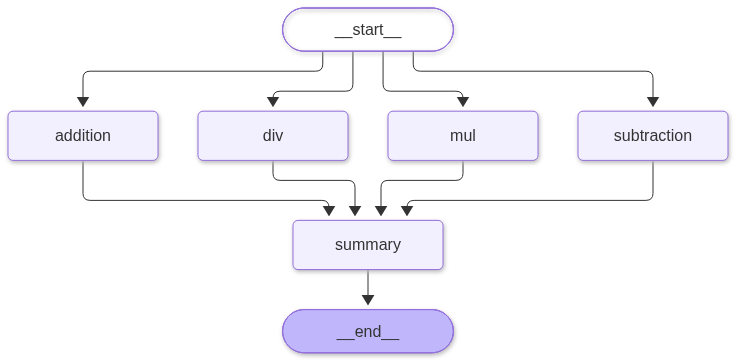

In [30]:
workflow